# Logistic Regression Baseline for UFC Winner Prediction

This notebook builds a baseline logistic regression model using the processed fight datasets.

## Imports: Libraries Used in This Notebook

This code block imports all required packages for:
1. Data loading and manipulation (`pandas`).
2. Plotting (`matplotlib`, `seaborn`).
3. Model building (`Pipeline`, `StandardScaler`, `LogisticRegression`).
4. Model evaluation (`accuracy`, `precision`, `recall`, `F1`, `ROC-AUC`, confusion matrix, and classification report).
5. Saving trained models (`joblib`).

In [ ]:
# Imports
from pathlib import Path

import joblib
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss,
    confusion_matrix,
    classification_report,
)

## Paths and Data Loading

This code block defines project/data/model paths, reads the train/validation/test processed CSV files, and prints their shapes so you can verify the splits loaded correctly.

In [2]:
# Paths
PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
DATA_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

train_path = DATA_DIR / "fights_training.csv"
val_path = DATA_DIR / "fights_validation.csv"
test_path = DATA_DIR / "fights_testing.csv"

train_df = pd.read_csv(train_path)
val_df = pd.read_csv(val_path)
test_df = pd.read_csv(test_path)


## Define Target Column and the Feature Columns and Split Each Data Frame to X and Y


In [3]:
TARGET = "winner"
dob = "diff_fighter_dob"
features = [col for col in train_df.columns if col != TARGET]

x_train = train_df[features]
y_train = train_df[TARGET]

x_val = val_df[features]
y_val = val_df[TARGET]

x_test = test_df[features]
y_test = test_df[TARGET]


## Build Scikit-Learn Pipline
1. Standarize data to ensure each feature has a mean of zero and a standard deviation of 1 (Standard Scalar)
2. Perform Logistic Regression

In [4]:
pipeline = Pipeline(steps=[("scaler", StandardScaler()),
    ("log_reg", LogisticRegression(random_state=42, max_iter=2000))])
pipeline.fit(x_train, y_train)
val_pred = pipeline.predict(x_val)
val_prob = pipeline.predict_proba(x_val)[:, 1]

# Test predictions
test_pred = pipeline.predict(x_test)
test_prob = pipeline.predict_proba(x_test)[:, 1]


## Metrics and Classification Reports

This code block computes validation and test metrics (accuracy, precision, recall, F1, ROC-AUC, log loss), displays them in a table, and prints class-by-class performance reports.

In [5]:
val_metrics = {
    "accuracy": accuracy_score(y_val, val_pred),
    "precision": precision_score(y_val, val_pred, zero_division=0),
    "recall": recall_score(y_val, val_pred, zero_division=0),
    "f1": f1_score(y_val, val_pred, zero_division=0),
    "log_loss": log_loss(y_val, val_prob),
}

test_metrics = {
    "accuracy": accuracy_score(y_test, test_pred),
    "precision": precision_score(y_test, test_pred, zero_division=0),
    "recall": recall_score(y_test, test_pred, zero_division=0),
    "f1": f1_score(y_test, test_pred, zero_division=0),
    "log_loss": log_loss(y_test, test_prob),
}

metrics_df = pd.DataFrame([val_metrics, test_metrics], index=["validation", "test"])
display(metrics_df)

print("\nValidation classification report:\"")
print(classification_report(y_val, val_pred, digits=4))

print("\nTest classification report:\"")
print(classification_report(y_test, test_pred, digits=4))

,accuracy,precision,recall,f1,log_loss
validation,0.572233,0.572233,0.572233,0.572233,0.684817
test,0.622659,0.622659,0.622659,0.622659,0.658194



Validation classification report:"
              precision    recall  f1-score   support

           0     0.5722    0.5722    0.5722       533
           1     0.5722    0.5722    0.5722       533

    accuracy                         0.5722      1066
   macro avg     0.5722    0.5722    0.5722      1066
weighted avg     0.5722    0.5722    0.5722      1066


Test classification report:"
              precision    recall  f1-score   support

           0     0.6227    0.6227    0.6227      1068
           1     0.6227    0.6227    0.6227      1068

    accuracy                         0.6227      2136
   macro avg     0.6227    0.6227    0.6227      2136
weighted avg     0.6227    0.6227    0.6227      2136



## Evaluation and Coefficient Interpretation

The next code block does two things:
1. Plots the confusion matrix on the test set so you can see true/false predictions by class.
2. Extracts logistic regression coefficients and displays the top features by absolute magnitude to highlight the strongest model signals.

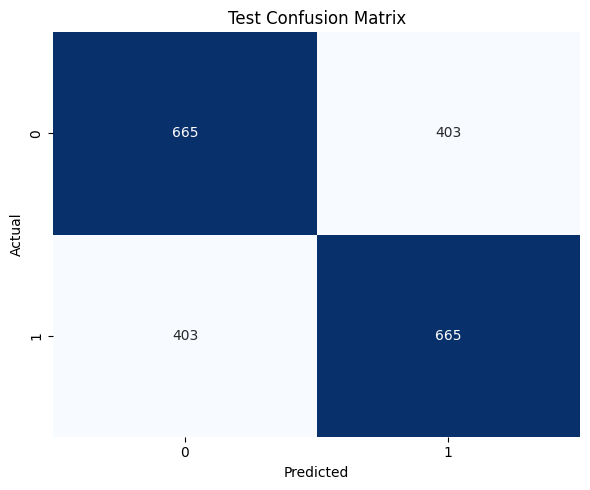

Top 15 features by absolute coefficient:


,feature,coefficient,abs_coef
20,diff_tot_strike_atts,-0.957890,0.957890
21,diff_tot_strikes,0.510566,0.510566
37,diff_ground_atts,0.379732,0.379732
15,diff_fighter_dob,0.319941,0.319941
29,diff_body_strike_atts,0.218704,0.218704
30,diff_body_strikes,-0.216024,0.216024
38,diff_grounds,-0.190193,0.190193
31,diff_leg_strike_atts,0.182702,0.182702
42,diff_losses,-0.168277,0.168277
18,diff_sig_strike_atts,0.159475,0.159475


In [6]:
cm = confusion_matrix(y_test, test_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Test Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

coef = pipeline.named_steps["log_reg"].coef_[0]
coef_df = pd.DataFrame({"feature": features, "coefficient": coef})
coef_df["abs_coef"] = coef_df["coefficient"].abs()

print("Top 15 features by absolute coefficient:")
display(coef_df.sort_values("abs_coef", ascending=False).head(15))

## Feature-Focused Accuracy Plots

This code block builds feature-level diagnostics from top coefficients by plotting accuracy across value bins for top features on the test set.
- Bins are ranges of data values grouped together to calculate model accuracy for samples in each group.

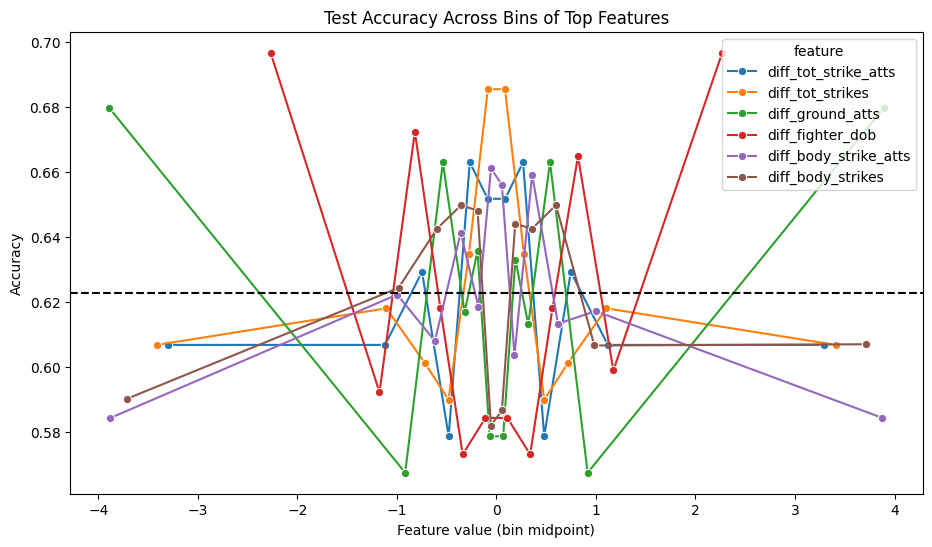

In [ ]:
# Top n features for focused accuracy plots
top_n = 6
top_features = coef_df.sort_values("abs_coef", ascending=False).head(top_n)["feature"].tolist()

# Accuracy by feature bins on the test set
plot_df = x_test[top_features].copy()
plot_df["correct"] = (test_pred == y_test.to_numpy()).astype(int)

binned_rows = []
for feature in top_features:
    try:
        bins = pd.qcut(plot_df[feature], q=10, duplicates="drop")
    except ValueError:
        continue

    feature_bins = pd.DataFrame({"bin": bins, "correct": plot_df["correct"]})
    summary = feature_bins.groupby("bin", observed=False)["correct"].mean().reset_index(name="accuracy")
    summary["feature"] = feature
    summary["bin_mid"] = summary["bin"].apply(lambda interval: interval.mid)
    binned_rows.append(summary)

if binned_rows:
    binned_accuracy = pd.concat(binned_rows, ignore_index=True)

    plt.figure(figsize=(11, 6))
    sns.lineplot(data=binned_accuracy, x="bin_mid", y="accuracy", hue="feature", marker="o")
    plt.axhline(accuracy_score(y_test, test_pred), color="black", linestyle="--", label="Overall test accuracy")
    plt.title("Test Accuracy Across Bins of Top Features")
    plt.xlabel("Feature value (bin midpoint)")
    plt.ylabel("Accuracy")
    plt.show()
else:
    print("Could not build binned feature plot (insufficient unique values).")

## Save the Trained Model

The next code block defines the output path for the trained logistic regression model and saves it as a `.joblib` artifact for reuse in later notebooks or scripts.

In [ ]:
model_path = MODEL_DIR / "logistic_regression_baseline.joblib"
joblib.dump(pipeline, model_path)
print(f"Saved model to: {model_path}")

Saved model to: /Users/andrewmattei/Machine-Learning-Project/models/logistic_regression_baseline.joblib
